# Predviđanje hit pesama na Spotify-ju: k najbližih suseda (kNN)

**Cilj:** predvideti da li će pesma biti hit, odnosno da li će biti u **gornjih 25% po broju slušanja**.

**Postupak:** pravljenje ciljne varijable, zamena nedostajućih vrednosti, izbor atributa, skaliranje unutar Pipeline-a (bez curenja podataka), izbor k pomoću 10-struke kros validacije i evaluacija.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
df = pd.read_csv('data/spotify.csv', encoding='latin1', na_values=['/', ' ', '', 'NA', '-'])
print(df.shape)
df.head()

(953, 13)
                            track_name  released_year  in_spotify_playlists  in_spotify_charts    streams  in_apple_playlists  in_apple_charts  bpm   mode  energy  instrumentalness  liveness  speechiness
0  Seven (feat. Latto) (Explicit Ver.)           2023                   553              147.0  141381703                  43            263.0  125  Major      83                 0         8            4
1                                 LALA           2023                  1474               48.0  133716286                  48            126.0   92  Major      74                 0        10            4
2                              vampire           2023                  1397              113.0  140003974                  94            207.0  138  Major      53                 0        31            6
3                         Cruel Summer           2019                  7858                NaN  800840817                 116            207.0  170  Major      72            

## 1. Ciljna varijabla
Pesma je hit (`HighStreams = 1`) ako joj je broj slušanja veći od trećeg kvartila. Kolonu `streams` zatim izbacujemo, jer bi inače model unapred "znao" odgovor. Izbacujemo i `track_name`, jer naziv pesme nije koristan atribut.

In [3]:
q3 = df['streams'].quantile(0.75)
df['HighStreams'] = (df['streams'] > q3).astype(int)
df = df.drop(columns=['streams', 'track_name'])
df['HighStreams'].value_counts(normalize=True).round(3)

HighStreams
0    0.75
1    0.25


## 2. Nedostajuće vrednosti
Shapiro-Wilk test pokazuje da kolone sa nedostajućim vrednostima nemaju normalnu raspodelu (p < 0,05), pa ih menjamo **medijanom**.

In [4]:
for col in ['in_spotify_charts', 'in_apple_charts']:
    print(col, 'Shapiro p =', shapiro(df[col].dropna()).pvalue)
    df[col] = df[col].fillna(df[col].median())
print('Preostalih nedostajućih vrednosti:', df.isna().sum().sum())

in_spotify_charts Shapiro p = 1.4519411043897098e-39
in_apple_charts Shapiro p = 4.467185022285124e-26
Preostalih nedostajućih vrednosti: 0


## 3. Izbor atributa
Atributi čije su raspodele iste kod hitova i ostalih pesama samo dodaju šum u kNN (svaki atribut ulazi u računanje rastojanja), pa ih izbacujemo.

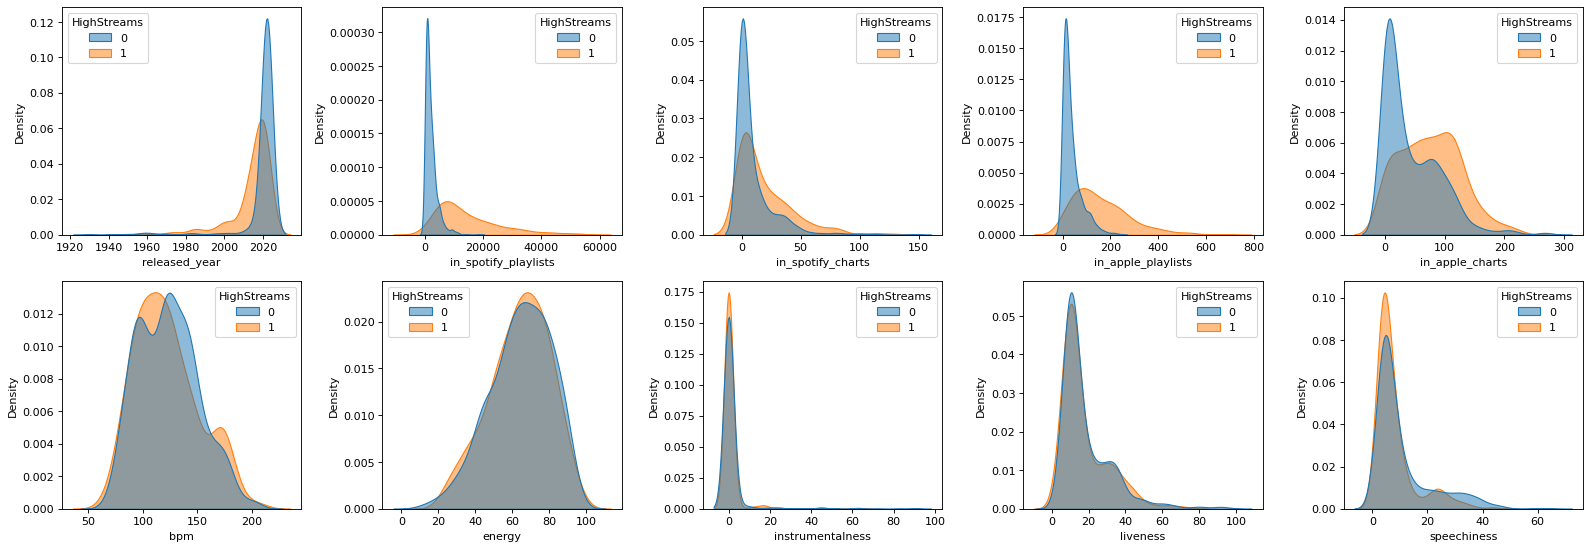

In [5]:
numeric = ['released_year', 'in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists',
           'in_apple_charts', 'bpm', 'energy', 'instrumentalness', 'liveness', 'speechiness']
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), numeric):
    sb.kdeplot(data=df, x=col, hue='HighStreams', fill=True, common_norm=False, alpha=0.5, ax=ax)
plt.tight_layout()
plt.show()

In [6]:
# bpm, energy, instrumentalness, liveness i speechiness imaju vrlo slične raspodele za obe klase
df = df.drop(columns=['bpm', 'energy', 'instrumentalness', 'liveness', 'speechiness'])
df['mode'] = df['mode'].map({'Major': 1, 'Minor': 0})
df.head()

   released_year  in_spotify_playlists  in_spotify_charts  in_apple_playlists  in_apple_charts  mode  HighStreams
0           2023                   553              147.0                  43            263.0     1            0
1           2023                  1474               48.0                  48            126.0     1            0
2           2023                  1397              113.0                  94            207.0     1            0
3           2019                  7858                3.0                 116            207.0     1            1
4           2023                  3133               50.0                  84            133.0     0            0


## 4. Skaliranje i izbor k
kNN se zasniva na rastojanjima, pa atributi moraju biti na sličnoj skali. Svi numerički atributi nemaju normalnu raspodelu i imaju outliere, pa koristimo **RobustScaler** (medijana i interkvartilni raspon).

Scaler je stavljen **unutar Pipeline-a**, tako da se tokom kros validacije fituje samo na trening delu i nikad ne vidi test podatke (nema curenja podataka).

In [7]:
X = df.drop(columns='HighStreams')
y = df['HighStreams']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipe = Pipeline([('scaler', RobustScaler()), ('knn', KNeighborsClassifier())])
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, {'knn__n_neighbors': list(range(3, 26, 2))}, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)
print('Optimalno k:', grid.best_params_['knn__n_neighbors'])
print('F1 u kros validaciji:', round(grid.best_score_, 3))

Optimalno k: 7
F1 u kros validaciji: 0.813


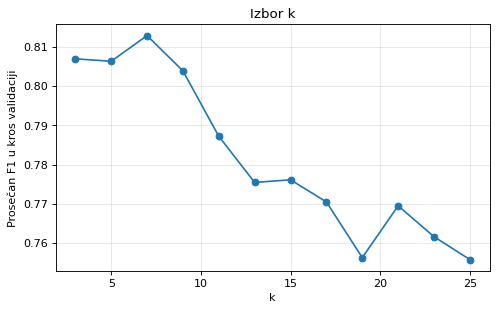

In [8]:
cv_res = pd.DataFrame(grid.cv_results_)
plt.figure(figsize=(7, 4))
plt.plot(cv_res['param_knn__n_neighbors'], cv_res['mean_test_score'], marker='o')
plt.xlabel('k'); plt.ylabel('Prosečan F1 u kros validaciji'); plt.title('Izbor k'); plt.grid(alpha=0.3)
plt.show()

## 5. Evaluacija na test skupu

              precision    recall  f1-score   support

    Nije hit      0.918     0.944     0.931       143
         Hit      0.818     0.750     0.783        48

    accuracy                          0.895       191
   macro avg      0.868     0.847     0.857       191
weighted avg      0.893     0.895     0.894       191



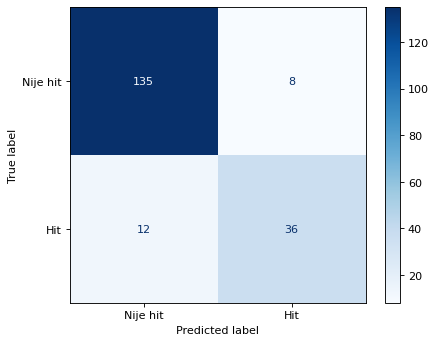

In [9]:
y_pred = grid.predict(X_test)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Nije hit', 'Hit']).plot(cmap=plt.cm.Blues)
plt.show()
print(classification_report(y_test, y_pred, target_names=['Nije hit', 'Hit'], digits=3))

## Zaključak
- Tačnost modela je **89,5%**, a F1 za hitove **0,78**.
- Prisustvo na plejlistama i top listama su najjači signali hita, dok se muzičke karakteristike (bpm, energy, liveness) skoro ne razlikuju između hitova i ostalih pesama.
- Precision za hitove je veći od recall-a: kada model kaže "hit" obično je u pravu, ali propusti deo hitova.
- Pipeline drži obradu podataka unutar kros validacije, pa je procena kvaliteta modela poštena.